# Importação de Bibliotecas

In [ ]:
# Importação framework para análise de dados
import pandas as pd
# Importação framework para operações matemáticas
import math
import numpy as np
# Importação framework para visualização de dados
import matplotlib.pyplot as plt
# Importação framework para visualização de dados
import seaborn as sns
# Importação framework para métricas de avaliação
from sklearn.metrics import confusion_matrix

# Tratamento de Dados

In [144]:
df = pd.read_csv(f'../Data/stm32report/all_models_1.csv', header=None, names=['index_execucao', 'modelo', 'ciclos', 'tempo_execucao', 'decisao'])
df['index_execucao'] = df['index_execucao'].str.replace('[', '').str.replace(']', '').astype(int)
df['modelo'] = df['modelo'].str.replace(' ', '')
df['ciclos'] = df['ciclos'].str.replace(' ciclos', '').astype(int)
df['tempo_execucao'] = df['tempo_execucao'].str.replace(' us', '').astype(int)
df['decisao'] = df['decisao'].str.replace(' decisao', '').astype(int)
df.head()

,index_execucao,modelo,ciclos,tempo_execucao,decisao
0,1,Fuzzy,12604,196,0
1,1,Logistica,5877,91,0
2,1,SVM,163086,2548,0
3,1,ArvoreDecisao,565,8,0
4,1,LGB,20783,324,0


In [145]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2400 entries, 0 to 2399
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   index_execucao  2400 non-null   int64
 1   modelo          2400 non-null   str  
 2   ciclos          2400 non-null   int64
 3   tempo_execucao  2400 non-null   int64
 4   decisao         2400 non-null   int64
dtypes: int64(4), str(1)
memory usage: 93.9 KB


# Análise de Resultados

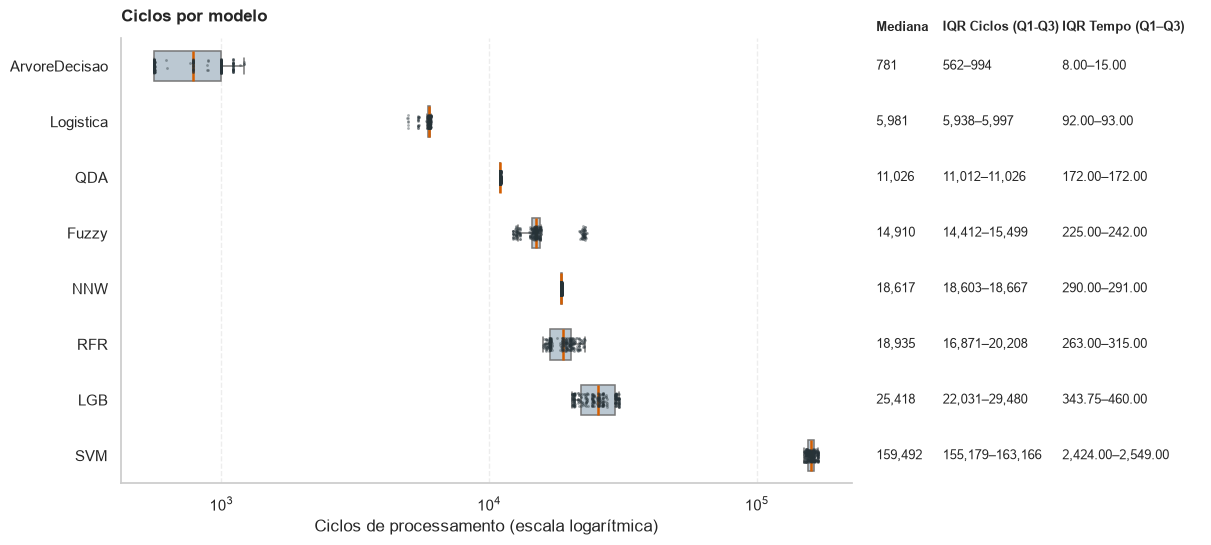

In [131]:
sub = df.copy()
sub["index_execucao"] = pd.to_numeric(sub["index_execucao"], errors="coerce")
sub["ciclos"] = pd.to_numeric(sub["ciclos"], errors="coerce")
sub["tempo_execucao"] = pd.to_numeric(sub["tempo_execucao"], errors="coerce")
sub = sub.dropna(subset=["index_execucao", "ciclos", "modelo", "tempo_execucao"])

ordem = (
    sub.groupby("modelo")["ciclos"]
       .median()
       .sort_values()
       .index
)

resumo = sub.groupby("modelo").agg(
    n=("ciclos", "size"),
    mediana=("ciclos", "median"),
    q1=("ciclos", lambda valores: valores.quantile(0.25)),
    q3=("ciclos", lambda valores: valores.quantile(0.75)),
    tempo_q1=("tempo_execucao", lambda valores: valores.quantile(0.25)),
    tempo_q3=("tempo_execucao", lambda valores: valores.quantile(0.75)),
).reindex(ordem)

fig = plt.figure(figsize=(12, max(4.5, 0.48 * len(ordem) + 1.5)), layout="constrained")
grid = fig.add_gridspec(1, 2, width_ratios=(5.5, 2.5), wspace=0.03)
ax = fig.add_subplot(grid[0, 0])
ax_resumo = fig.add_subplot(grid[0, 1], sharey=ax)

sns.boxplot(
    data=sub, x="ciclos", y="modelo",
    order=ordem, showfliers=False, width=0.55,
    color="#B7C9D6", linewidth=1.1,
    medianprops={"color": "#D55E00", "linewidth": 1.8},
    ax=ax,
)
sns.stripplot(
    data=sub, x="ciclos", y="modelo",
    order=ordem, jitter=0.12, alpha=0.4,
    size=2, color="#263238", ax=ax,
)

ax.set_xscale("log")
ax.set_title("Ciclos por modelo", loc="left", weight="bold", pad=12)
ax.set_xlabel("Ciclos de processamento (escala logarítmica)")
ax.set_ylabel("")
ax.grid(axis="x", which="major", linestyle="--", alpha=0.35)
ax.grid(axis="x", which="minor", visible=False)
ax.set_axisbelow(True)
sns.despine(ax=ax)

ax_resumo.set_xlim(0, 1)
ax_resumo.set_ylim(ax.get_ylim())
ax_resumo.set_axis_off()

for x, titulo in ((0.02, "Mediana"), (0.22, "IQR Ciclos (Q1-Q3)"), (0.58, "IQR Tempo (Q1–Q3)")):
    ax_resumo.text(x, 1.01, titulo, transform=ax_resumo.transAxes,
                   ha="left", va="bottom", weight="bold", fontsize=9)
for pos, modelo in enumerate(ordem):
    linha = resumo.loc[modelo]
    iqr = f"{linha['q1']:,.0f}–{linha['q3']:,.0f}"
    iqr_tempo = f"{linha['tempo_q1']:,.2f}–{linha['tempo_q3']:,.2f}"
    ax_resumo.text(0.02, pos, f"{linha['mediana']:,.0f}", ha="left", va="center", fontsize=9)
    ax_resumo.text(0.22, pos, iqr, ha="left", va="center", fontsize=9)
    ax_resumo.text(0.58, pos, iqr_tempo, ha="left", va="center", fontsize=9)

plt.show()

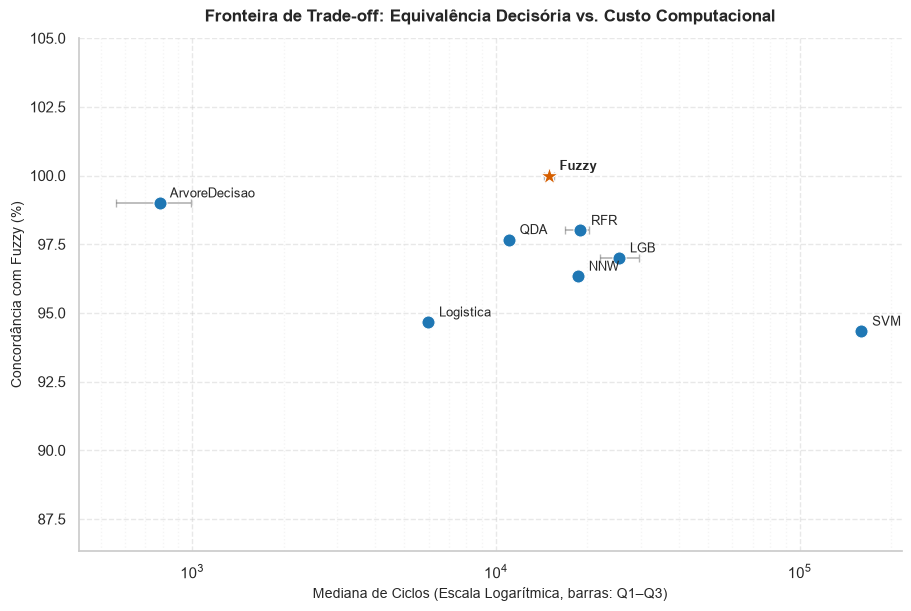

In [147]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

modelo_base = "Fuzzy"

# 1. Limpeza dos dados
df_clean = sub.dropna(subset=["index_execucao", "modelo", "ciclos", "decisao"]).copy()
df_clean["ciclos"] = pd.to_numeric(df_clean["ciclos"], errors="coerce")
df_clean["decisao"] = pd.to_numeric(df_clean["decisao"], errors="coerce")

# 2. Pivotar para calcular a concordância pareada com o modelo base
pivot_decisoes = df_clean.pivot_table(
    index="index_execucao",
    columns="modelo",
    values="decisao",
    aggfunc="first"
)

# 3. Métricas de custo (Ciclos: Q1, Mediana, Q3) e Concordância
estatisticas = []

for modelo in pivot_decisoes.columns:
    dados_modelo = df_clean[df_clean["modelo"] == modelo]["ciclos"].dropna()
    
    mediana_ciclos = dados_modelo.median()
    q1_ciclos = dados_modelo.quantile(0.25)
    q3_ciclos = dados_modelo.quantile(0.75)
    
    if modelo == modelo_base:
        concordancia = 100.0
    else:
        validos = pivot_decisoes[[modelo_base, modelo]].dropna()
        concordancia = (validos[modelo_base] == validos[modelo]).mean() * 100.0 if len(validos) > 0 else np.nan
        
    estatisticas.append({
        "modelo": modelo,
        "mediana_ciclos": mediana_ciclos,
        "q1_ciclos": q1_ciclos,
        "q3_ciclos": q3_ciclos,
        "concordancia": concordancia
    })

df_pareto = pd.DataFrame(estatisticas).dropna(subset=["concordancia", "mediana_ciclos"])

# 4. Plotagem
fig, ax = plt.subplots(figsize=(9, 6), layout="constrained")

for _, linha in df_pareto.iterrows():
    mod = linha["modelo"]
    x = linha["mediana_ciclos"]
    y = linha["concordancia"]
    x_err_min = x - linha["q1_ciclos"]
    x_err_max = linha["q3_ciclos"] - x
    
    eh_base = (mod == modelo_base)
    cor = "#D55E00" if eh_base else "#1F77B4"
    marcador = "*" if eh_base else "o"
    tamanho = 180 if eh_base else 90
    
    # Barra de erro horizontal representando o intervalo [Q1, Q3]
    ax.errorbar(
        x, y, 
        xerr=[[x_err_min], [x_err_max]], 
        fmt="none", 
        ecolor="gray", 
        elinewidth=1.2, 
        capsize=3, 
        alpha=0.6, 
        zorder=2
    )
    
    # Ponto central (Mediana)
    ax.scatter(x, y, color=cor, marker=marcador, s=tamanho, zorder=3, edgecolors="white", linewidth=0.8)
    
    # Rótulo de texto do modelo
    ax.annotate(
        f" {mod}", 
        (x, y), 
        xytext=(5, 4), 
        textcoords="offset points", 
        fontsize=9, 
        weight="bold" if eh_base else "normal"
    )

ax.set_xscale("log")
ax.set_ylim(max(0, df_pareto["concordancia"].min() - 8), 105)

ax.set_title("Fronteira de Trade-off: Equivalência Decisória vs. Custo Computacional", weight="bold", pad=12, loc="center")
ax.set_xlabel("Mediana de Ciclos (Escala Logarítmica, barras: Q1–Q3)", fontsize=10)
ax.set_ylabel(f"Concordância com {modelo_base} (%)", fontsize=10)

ax.grid(True, which="major", linestyle="--", alpha=0.45)
ax.grid(True, which="minor", linestyle=":", alpha=0.2)
ax.set_axisbelow(True)
sns.despine(ax=ax)

plt.show()

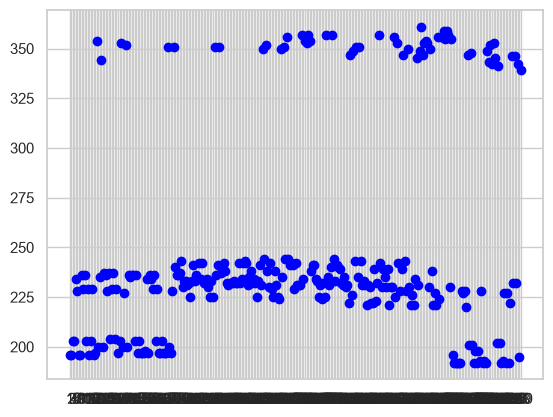

In [62]:
MODEL = 'Fuzzy'
plt.scatter(df['index_execucao'].loc[df['modelo'] == MODEL], df['tempo_execucao'].loc[df['modelo'] == MODEL], label=MODEL, color='blue')